In [17]:
import gc
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap


from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance




<h2>Read-in Data</h2>

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'SO2 Mass (short tons)': 'float32',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (short tons/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'SO2 Mass (lbs)': 'float32',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'SO2 Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'SO2 Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [5]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_ny["Date"] = pd.to_datetime(campd_ny["Date"])
campd_ny["datetime"] = pd.to_datetime(campd_ny["datetime"])

<h2>Preprocessing Methods</h2>

In [ ]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime({
    'year': df["Date"].dt.year,
    'month': df["Date"].dt.month,
    'day': df["Date"].dt.day,
    'hour': df["Hour"]
    })


    return df


In [ ]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_ny, ny_code_cols = preprocess_program_codes(campd_ny)
# ny_code_cols

<h2>Model-independent Preprocessing</h2>

- create time-lags
- manually OHE SO2 controls and program codes
- downsample the non-operating rows by 90%
- remove rows where SO2 was not fully measured

In [ ]:
# read in previous year to get according lags
campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
campd_ny_2018 = campd_ny_2018[["Facility ID", "Unit ID", "Date", "Hour", "SO2 Mass (lbs)"]]
campd_ny_2018["datetime"] = pd.to_datetime({
    'year': campd_ny_2018["Date"].dt.year,
    'month': campd_ny_2018["Date"].dt.month,
    'day': campd_ny_2018["Date"].dt.day,
    'hour': campd_ny_2018["Hour"]
    })
campd_ny_2018["SO2 Mass (lbs)"] = campd_ny_2018["SO2 Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_ny, campd_ny_2018, "SO2 Mass (lbs)")

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_with_SO2_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_with_SO2_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [ ]:
# manually one-hot encode program codes
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [ ]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [ ]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", dtype=campd_type_dict)

In [ ]:
campd_df["SO2 Mass Measure Indicator"].value_counts()

SO2 Mass Measure Indicator
Measured                   2280325
Nothing                    1162797
LME                          72482
Substitute                   31730
Measured and Substitute      16164
Name: count, dtype: Int64

In [ ]:
campd_df = campd_df[(campd_df["SO2 Mass Measure Indicator"] == "Measured") | (campd_df["SO2 Mass Measure Indicator"] == "Nothing")]
campd_df["SO2 Mass Measure Indicator"].value_counts()

SO2 Mass Measure Indicator
Measured    2280325
Nothing     1162797
Name: count, dtype: Int64

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False, compression="gzip")

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz")

C:\Users\marce\AppData\Local\Temp\ipykernel_1792\305730329.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz")


In [5]:
campd_df.shape

(3443122, 80)

In [ ]:
campd_ny["SO2 Controls"].unique()

<StringArray>
['Nothing', 'Dry Lime FGD', 'Wet Limestone']
Length: 3, dtype: string

<h2>Regression Models</h2>

- for each model type, we preprocess data appropriately and evaluate models with default parameters using 2019-2023 training data and 2024 as the test data
-> prepare models for xAI analysis

<h3>Linear Regression</h3>

- build ridge regression models without and with lags
- LR cannot handle nulls inherently -> remove nan cols with >50% (summer/winter capacity + min load) and filter out any remaining rows with null values

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [6]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] #+ lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols)


In [7]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]


# remove nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              5.967985
Latitude                    10.302394
Longitude                   10.302394
Nameplate Capacity (MWe)    10.302394
hourly_capacity_factor       6.935827
hourly_ramping_factor       16.271541
Summer Capacity (MW)        58.785922
Winter Capacity (MW)        58.785922
Minimum Load (MW)           58.785922
Temperature (F)              1.696861
dtype: float64

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [22]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols)


target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

<h4>No Lags</h4>

R^2 Score: 0.0539
Mean Squared Error (MSE): 2908.2412
Root Mean Squared Error (RMSE): 53.9281
Normalized RMSE (by std): 0.9727


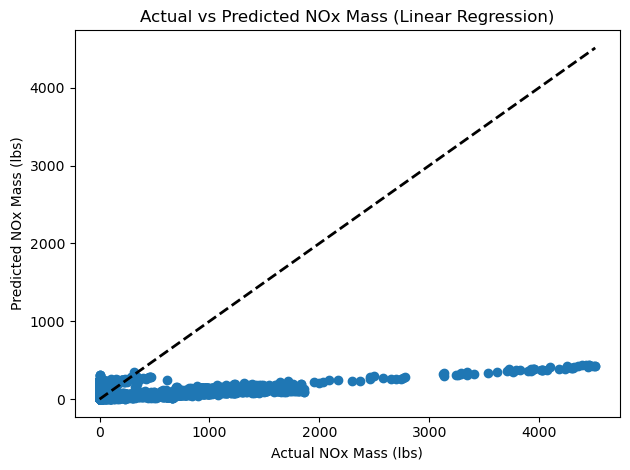

In [21]:
# default model (no lags, no unmeasured, with temps)

# Ridge Regression

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()


<h4>With Lags</h4>

In [24]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any remaining NaN values (lags)
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9530
Mean Squared Error (MSE): 144.5632
Root Mean Squared Error (RMSE): 12.0234
Normalized RMSE (by std): 0.2169


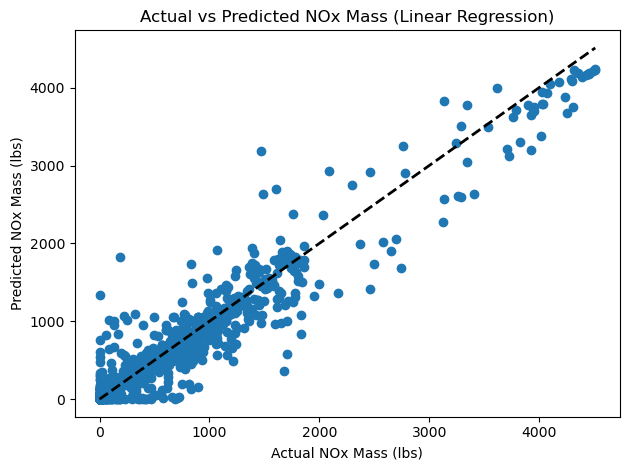

In [25]:
# default model (no lags, no unmeasured, with temps)

# Ridge Regression

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()


<h3>XGBoost</h3>

<h6>Preprocessing</h6>

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
campd_df["Calc SO2 Mass (lbs)"] = np.nan
campd_df.loc[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas", "Calc SO2 Mass (lbs)"] = 0.0006 * campd_df["Heat Input (mmBtu)"]
campd_df["Difference Calc/Meas"] = campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 Mass (lbs)"]
#campd_df.sort_values(by="Difference Calc/Meas", ascending=False).head()

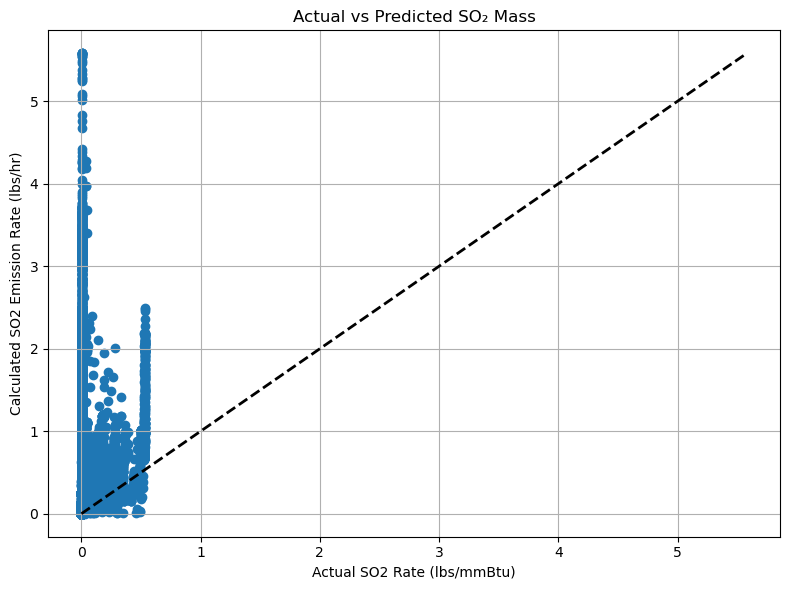

R² Score: -1105.1446
Mean Squared Error (MSE): 0.4917
Root Mean Squared Error (RMSE): 0.7012
Normalized RMSE (by std): 33.3092


In [ ]:

# Recalculate predicted SO2 emission rate only for Pipeline Natural Gas
campd_df["Calc SO2 Mass (lbs)"] = np.nan
campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 Mass (lbs)"
] = 0.0006 * campd_df["Heat Input (mmBtu)"]

# Calculate difference
campd_df["Difference Calc/Meas"] = (
    campd_df["SO2 Rate (lbs/mmBtu)"] - campd_df["Calc SO2 Mass (lbs)"]
)

# Filter for Pipeline Natural Gas and SO2 values
mask = (
    (campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") &
    (campd_df["SO2 Rate (lbs/mmBtu)"] < 3) &
    (campd_df["Year"] == 2019)
)

filtered_df = campd_df[mask]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    filtered_df["SO2 Rate (lbs/mmBtu)"],
    filtered_df["Calc SO2 Mass (lbs)"]
)
plt.xlabel("Actual SO2 Rate (lbs/mmBtu)")
plt.ylabel("Calculated SO2 Emission Rate (lbs/hr)")
plt.title("Actual vs Predicted SO₂ Mass")

# 1:1 reference line
min_val = min(filtered_df["SO2 Rate (lbs/mmBtu)"].min(), filtered_df["Calc SO2 Mass (lbs)"].min())
max_val = max(filtered_df["SO2 Rate (lbs/mmBtu)"].max(), filtered_df["Calc SO2 Mass (lbs)"].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(filtered_df["SO2 Rate (lbs/mmBtu)"], filtered_df["Calc SO2 Mass (lbs)"])
mse = mean_squared_error(filtered_df["SO2 Rate (lbs/mmBtu)"], filtered_df["Calc SO2 Mass (lbs)"])
rmse = np.sqrt(mse)
nrmse = rmse / np.std(filtered_df["SO2 Rate (lbs/mmBtu)"])

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

In [7]:
pd.set_option('display.float_format', '{:.2f}'.format)

campd_df["SO2 Mass (lbs)"].describe()

count   3443122.00
mean          4.82
std          80.71
min           0.00
25%           0.00
50%           0.29
75%           0.99
max        5029.30
Name: SO2 Mass (lbs), dtype: float64

In [ ]:
# Split the data
below_3 = filtered_df[filtered_df["SO2 Mass (lbs)"] < 3]
above_3 = filtered_df[filtered_df["SO2 Mass (lbs)"] >= 3]

# Define a function to compute metrics
def evaluate_performance(df, label):
    y_true = df["SO2 Mass (lbs)"]
    y_pred = df["Calc SO2 Mass (lbs)"]
    
    if len(df) == 0:
        print(f"\n{label}: No data points.")
        return
    
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse / np.std(y_true)

    print(f"\n{label}")
    print(f"R² Score: {r2:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Normalized RMSE (by std): {nrmse:.4f}")

# Evaluate both subsets
evaluate_performance(below_3, "SO₂ < 3 lbs")
evaluate_performance(above_3, "SO₂ ≥ 3 lbs")

# formula performs well below 3 lbs, but it is very mixed (see above), we cannot accurately discern whether oil was used, and filtering by 
# realistic gas SO2 rates is not possible since they vary greatly


SO₂ < 3 lbs
R² Score: 0.9880
Mean Squared Error (MSE): 0.0028
Root Mean Squared Error (RMSE): 0.0526
Normalized RMSE (by std): 0.1096

SO₂ ≥ 3 lbs
R² Score: -0.2930
Mean Squared Error (MSE): 133950.7541
Root Mean Squared Error (RMSE): 365.9928
Normalized RMSE (by std): 1.1371


In [14]:
campd_df[(campd_df["Heat Input (mmBtu)"] == campd_df[(campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") & (campd_df["Year"] == 2019)]["Heat Input (mmBtu)"].max())]

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas
477825,2019-08-09 13:00:00,NY,Ravenswood Generating Station,2500,30,2019-08-09,13,1.00,988.00,NaN,5.58,Measured,0.00,Calculated,552.60,Measured,0.06,Calculated,892.60,Measured,0.10,Measured,9298.10,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,Nothing,"ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.76,-73.95,Phase 2,Nothing,Operating,9379.00,3 (1027.7),1027.70,8,0.96,-0.00,988.50,977.80,150.00,1965.00,1965.00,1965.00,<NA>,54,54,54.00,9.00,NYC,80.00,5.58,5.55,0.21,0.00,0.00,0.00,4.15,1,1,1,0,0,1,1,0,0,1,0,-0.26,-0.97,0.97,-0.22,-0.87,-0.50,5.58,0.00


In [16]:
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [25]:
campd_df[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas"]["SO2 Rate (lbs/mmBtu)"].describe()

count   2881575.0000
mean          0.0024
std           0.0280
min           0.0000
25%           0.0000
50%           0.0010
75%           0.0010
max          11.8000
Name: SO2 Rate (lbs/mmBtu), dtype: float64

In [ ]:
campd_df[(campd_df["Facility ID"] == 2516) & (campd_df["Unit ID"] == "4") & (campd_df["datetime"].dt.date == pd.to_datetime("2019-12-19").date())].sort_values(by="datetime")


# large shift in SO2 Rate (and SO2 and SO2 rate) -> likely fuel switch to oil
# big jump in SO2 emissions
# -> we want to exclude these unrealistically high rates for gas SO2 prediction

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas
894494,2019-12-19 00:00:00,NY,Northport,2516,4,2019-12-19,0,1.00,161.00,NaN,1.09,Measured,0.00,Calculated,107.70,Measured,0.06,Calculated,56.20,Measured,0.03,Measured,1812.90,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.42,0.05,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,19.90,0.96,0.89,1.06,0.91,1.15,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.00,1.00,-0.97,-0.22,-0.00,1.00,1.09,0.00
894495,2019-12-19 01:00:00,NY,Northport,2516,4,2019-12-19,1,1.00,190.00,NaN,1.26,Measured,0.00,Calculated,124.90,Measured,0.06,Calculated,79.90,Measured,0.04,Measured,2102.30,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.49,0.07,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,19.90,1.09,0.96,1.06,0.90,0.97,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.26,0.97,-0.97,-0.22,-0.00,1.00,1.26,-0.00
894496,2019-12-19 02:00:00,NY,Northport,2516,4,2019-12-19,2,1.00,190.00,NaN,1.26,Measured,0.00,Calculated,125.10,Measured,0.06,Calculated,80.00,Measured,0.04,Measured,2104.40,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.49,0.00,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,18.00,1.26,1.09,1.04,0.89,0.97,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.50,0.87,-0.97,-0.22,-0.00,1.00,1.26,0.00
894497,2019-12-19 03:00:00,NY,Northport,2516,4,2019-12-19,3,1.00,190.00,NaN,1.27,Measured,0.00,Calculated,125.90,Measured,0.06,Calculated,80.50,Measured,0.04,Measured,2118.70,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.49,0.00,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,18.00,1.26,1.26,1.04,1.20,0.98,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.71,0.71,-0.97,-0.22,-0.00,1.00,1.27,-0.00
894498,2019-12-19 04:00:00,NY,Northport,2516,4,2019-12-19,4,1.00,212.00,NaN,1.41,Measured,0.00,Calculated,139.50,Measured,0.06,Calculated,91.50,Measured,0.04,Measured,2347.00,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa..."

In [ ]:
filtered_df.sort_values(by="Difference Calc/Meas").head(3)

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas
1197321,2020-06-10 18:00:00,NY,Bowline Generating Station,2625,2,2020-06-10,18,1.0000,567.0000,NaN,0.0000,Measured,0.0000,Calculated,358.9000,Measured,0.0590,Calculated,829.5000,Measured,0.1370,Measured,6055.1000,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Overfire Air,"ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2020,Electric Utility,41.2044,-73.9689,Phase 2,Nothing,Operating,7600.0000,2 (640),640.0000,6,0.8859,0.0000,562.0000,567.0000,100.0000,1974.0000,1974.0000,1974.0000,<NA>,46,46,46.0000,10.0000,HPN,73.0000,1.3000,1.3000,2.5000,0.0000,0.0000,0.0000,0.0000,1,1,1,0,0,1,1,0,0,1,0,-1.0000,-0.0000,0.4339,-0.9010,0.0000,-1.0000,3.6331,-3.6331
1200830,2022-02-03 15:00:00,NY,Bowline Generating Station,2625,2,2022-02-03,15,1.0000,535.0000,NaN,0.0000,Measured,0.0000,Calculated,349.6000,Measured,0.0590,Calculated,725.3000,Measured,0.1230,Measured,5896.8000,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Overfire Air,"ARP, CSNOX, CSOSG3, CSSO2G1, MATS, RGGI",2022,Electric Utility,41.2044,-73.9689,Phase 2,Nothing,Operating,7600.0000,2 (640),640.0000,2,0.8359,0.0281,573.6000,568.8000,100.0000,1974.0000,1974.0000,1974.0000,<NA>,48,48,48.0000,3.0000,HPN,42.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,1,0,0,1,1,1,0,0,1,0,-0.7071,-0.7071,0.4339,-0.9010,0.8660,0.5000,3.5381,-3.5381
1200745,2022-01-28 00:00:00,NY,Bowline Generating Station,2625,2,2022-01-28,0,1.0000,555.0000,NaN,0.0000,Measured,0.0000,Calculated,340.1000,Measured,0.0590,Calculated,682.8000,Measured,0.1190,Measured,5737.5000,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Overfire Air,"ARP, CSNOX, CSOSG3, CSSO2G1, MATS, RGGI",2022,Electric Utility,41.2044,-73.9689,Phase 2,Nothing,Operating,7600.0000,2 (640),640.0000,1,0.8672,0.0219,573.6000,568.8000,100.0000,1974.0000,1974.0000,1974.0000,<NA>,48,48,48.0000,28.0000,HPN,28.0000,0.0000,0.0000,0.0000,8.4000,7.3000,0.0000,24.4000,1,1,0,0,1,1,1,0,0,1,0,0.0000,1.0000,-0.0000,1.0000,0.5000,0.8660,3.4425,-3.4425


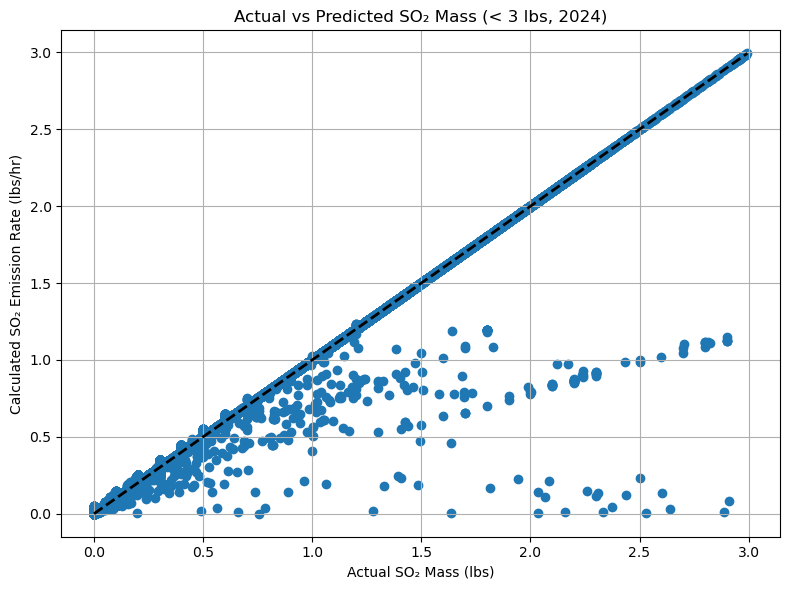

R² Score: 0.9978
Mean Squared Error (MSE): 0.0006
Root Mean Squared Error (RMSE): 0.0246
Normalized RMSE (by std): 0.0474


In [9]:

# Recalculate predicted SO2 emission rate only for Pipeline Natural Gas
campd_df["Calc SO2 Mass (lbs)"] = np.nan
campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 Mass (lbs)"
] = 0.0006 * campd_df["Heat Input (mmBtu)"]

# Calculate difference
campd_df["Difference Calc/Meas"] = (
    campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 Mass (lbs)"]
)

# Filter for Pipeline Natural Gas and SO2 rates < 3 lbs
mask = (
    (campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") &
    (campd_df["Year"] == 2024) &
    (campd_df["SO2 Mass (lbs)"] < 3) 

)

filtered_df = campd_df[mask]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    filtered_df["SO2 Mass (lbs)"],
    filtered_df["Calc SO2 Mass (lbs)"]
)
plt.xlabel("Actual SO₂ Mass (lbs)")
plt.ylabel("Calculated SO₂ Emission Rate (lbs/hr)")
plt.title("Actual vs Predicted SO₂ Mass (< 3 lbs, 2024)")

# 1:1 reference line
min_val = min(filtered_df["SO2 Mass (lbs)"].min(), filtered_df["Calc SO2 Mass (lbs)"].min())
max_val = max(filtered_df["SO2 Mass (lbs)"].max(), filtered_df["Calc SO2 Mass (lbs)"].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 Mass (lbs)"])
mse = mean_squared_error(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 Mass (lbs)"])
rmse = np.sqrt(mse)
nrmse = rmse / np.std(filtered_df["SO2 Mass (lbs)"])

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

# for emissions over 3 lbs, we reasonably assume that the SO2 emissions are not from Pipeline Natural Gas, but rather from secondary fuel oil
# -> we filter those out

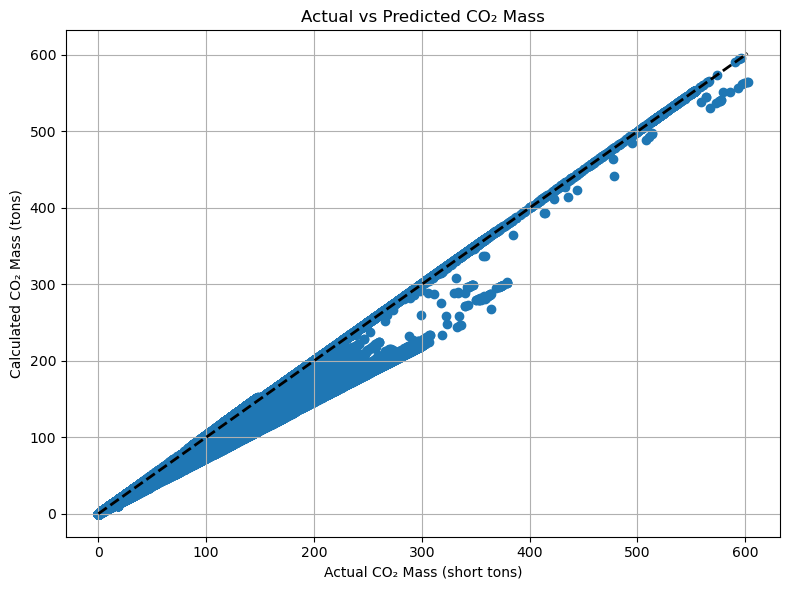

R² Score: 0.9975
Mean Squared Error (MSE): 7.1270
Root Mean Squared Error (RMSE): 2.6696
Normalized RMSE (by std): 0.0505


In [ ]:

# Define actual and predicted values
y_actual = campd_df["SO2 Mass (short tons)"]
y_predicted = campd_df["Calc SO2 emission rate (tons)"]

# Drop rows with NaNs in either column
valid_mask = y_actual.notna() & y_predicted.notna()
y_actual_clean = y_actual[valid_mask]
y_predicted_clean = y_predicted[valid_mask]

# Scatter plot: Actual vs Predicted SO2 Mass
plt.figure(figsize=(8, 6))
plt.scatter(y_actual_clean, y_predicted_clean)
plt.xlabel("Actual SO₂ Mass (short tons)")
plt.ylabel("Calculated SO₂ Mass (tons)")
plt.title("Actual vs Predicted CO₂ Mass")

# 1:1 reference line
min_val = min(y_actual_clean.min(), y_predicted_clean.min())
max_val = max(y_actual_clean.max(), y_predicted_clean.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(y_actual_clean, y_predicted_clean)
mse = mean_squared_error(y_actual_clean, y_predicted_clean)
rmse = np.sqrt(mse)
nrmse = rmse / np.std(y_actual_clean)

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

In [ ]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'SO2 Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type', 'SO2 Controls']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_factor',
                                  'Summer Capacity (MW)',
                                  'Winter Capacity (MW)', 'Minimum Load (MW)',
                                  'Year', 'Temperature (F)']),
                                ('encoded', 'passthrough',
                                 ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3',
                                  'CSSO2G1', 'MATS', 'Missing', 'NSPS4T',
                                  'RGGI', 'SIPNOX'])])

In [ ]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train.csv", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test.csv", index=False)
y_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_train.csv", index=False)
y_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_test.csv", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test.csv", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_train.csv")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_test.csv")

In [18]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train_processed.csv", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test_processed.csv", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train_processed.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test_processed.csv", dtype=campd_type_dict)

In [19]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [13]:
dtrain.save_binary("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtrain_ny_full_2019_2023.buffer")
dtest.save_binary("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtest_ny_full_2024.buffer")

In [4]:
dtrain = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtrain_ny_full_2019_2023.buffer")
dtest = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtest_ny_full_2024.buffer")

<h6>Train All, Test Year 2024</h6>

In [ ]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

R^2 Score: 0.7762
Mean Squared Error (MSE): 578.4150
Root Mean Squared Error (RMSE): 24.0503
Normalized RMSE (by std): 0.4731


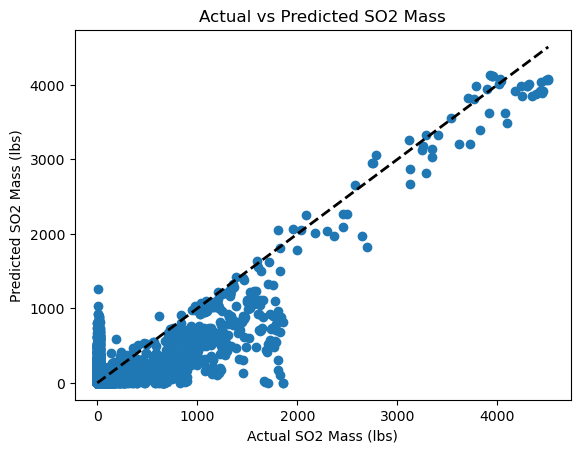

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9718
Mean Squared Error (MSE): 72.7744
Root Mean Squared Error (RMSE): 8.5308
Normalized RMSE (by std): 0.1678


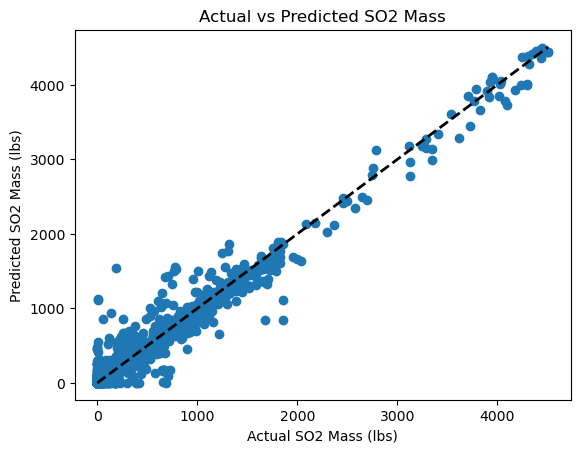

In [ ]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [22]:
# load saved models
xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model(("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json"))

In [ ]:
xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

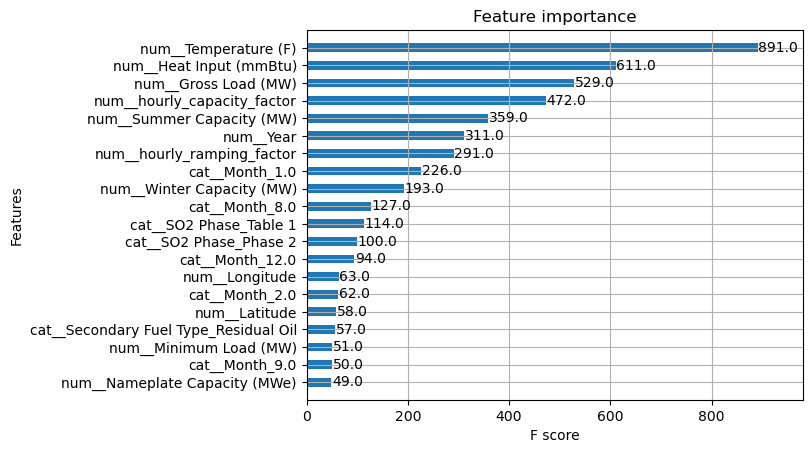

In [19]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

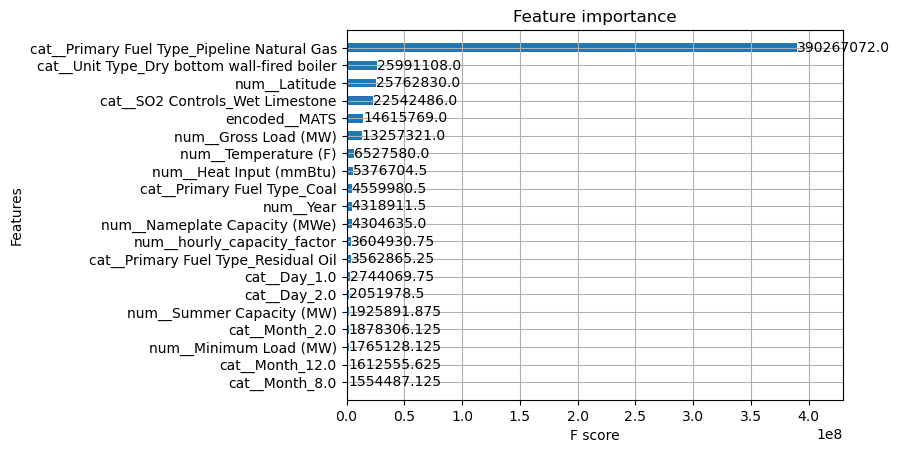

In [20]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

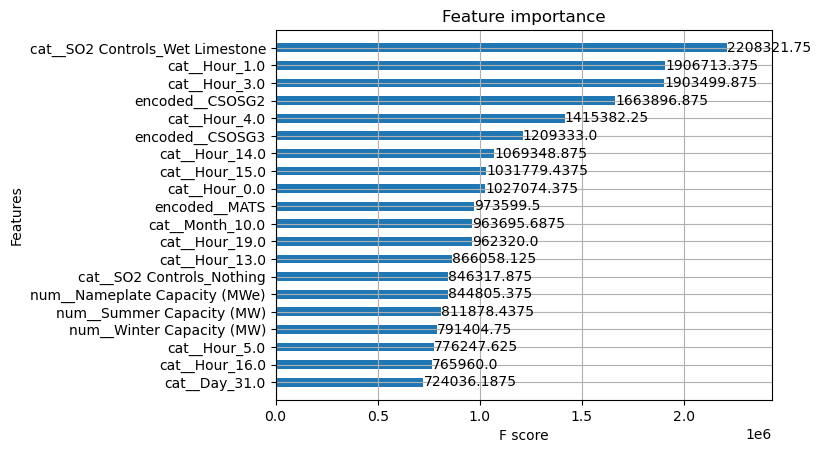

In [21]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Permutation Importance</h3>

In [20]:
xgb_default_model = xgb.Booster()
xgb_default_model.load_model("xgb_default_model_ny.json")

In [22]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

<h4>Ungrouped</h4>

In [24]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
30,num__Heat Input (mmBtu),4211.327564,7.920819
73,encoded__lag_1_hour,2744.528883,20.343737
29,num__Gross Load (MW),790.022592,1.839927
34,num__hourly_capacity_factor,454.371509,6.923041
33,num__Nameplate Capacity (MWe),295.352342,1.966193
...,...,...,...
41,encoded__Combustion Modification/Fuel Reburning,0.000000,0.000000
79,encoded__lag_1_year,-0.072600,0.081690
68,encoded__Hour_cos,-0.278409,0.233878
78,encoded__lag_1_month,-0.310213,0.263384


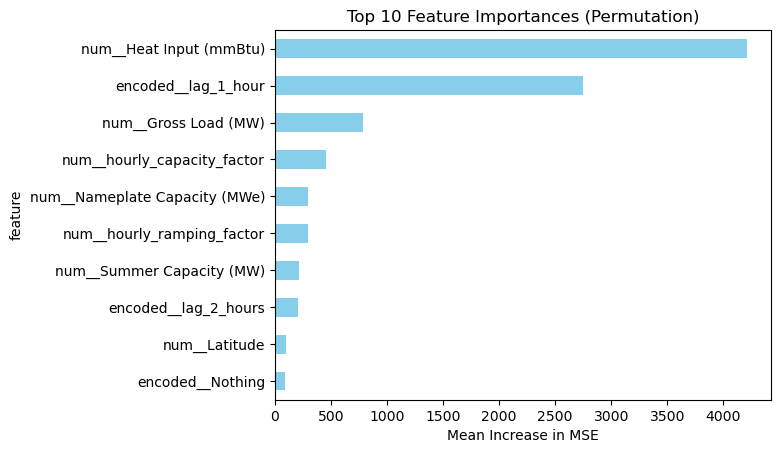

In [25]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h4>Grouped</h4>

In [ ]:
# select only one feature per group of features

In [29]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_test")

In [ ]:
# group features over 80% correlation and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.9794
Mean Squared Error (MSE): 75.7565
Root Mean Squared Error (RMSE): 8.7038


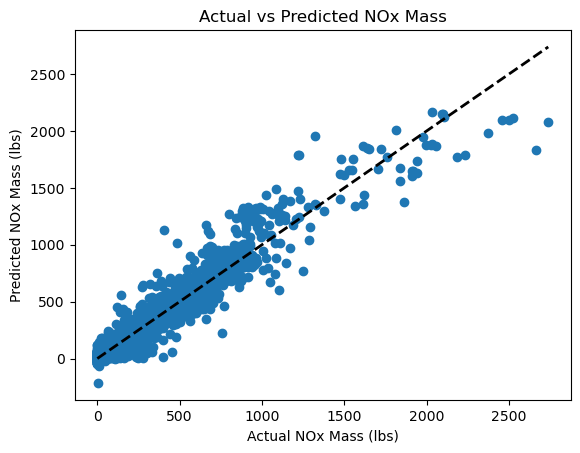

In [ ]:
# Model with default parameters and grouped features (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [34]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

In [35]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

In [36]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


                              feature  importance_mean  importance_std
29            num__Heat Input (mmBtu)      2521.251736       18.969534
69                encoded__lag_1_hour      2490.092606        8.547923
70               encoded__lag_2_hours       319.698196        0.930906
33         num__hourly_ramping_factor       316.903995        1.990838
32      num__Nameplate Capacity (MWe)       305.800272        1.545558
..                                ...              ...             ...
74               encoded__lag_1_month        -0.217195        0.126999
68                 encoded__Month_cos        -0.252525        0.618682
13  cat__Unit Type_Tangentially-fired        -0.697302        0.153008
66                   encoded__Day_cos        -1.132652        0.368939
63                  encoded__Hour_sin        -1.441972        0.267040

[76 rows x 3 columns]


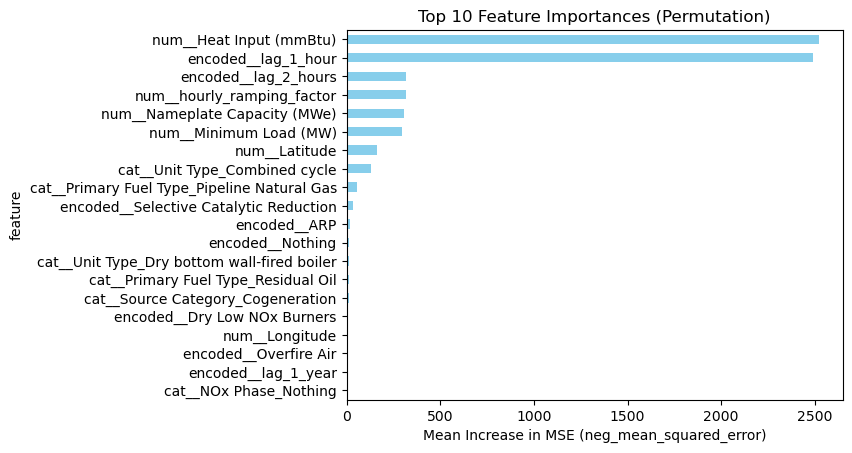

In [38]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h5>No Lags</h5>

In [23]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [24]:
shap_values = explainer(X_test, approximate=False)

In [25]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

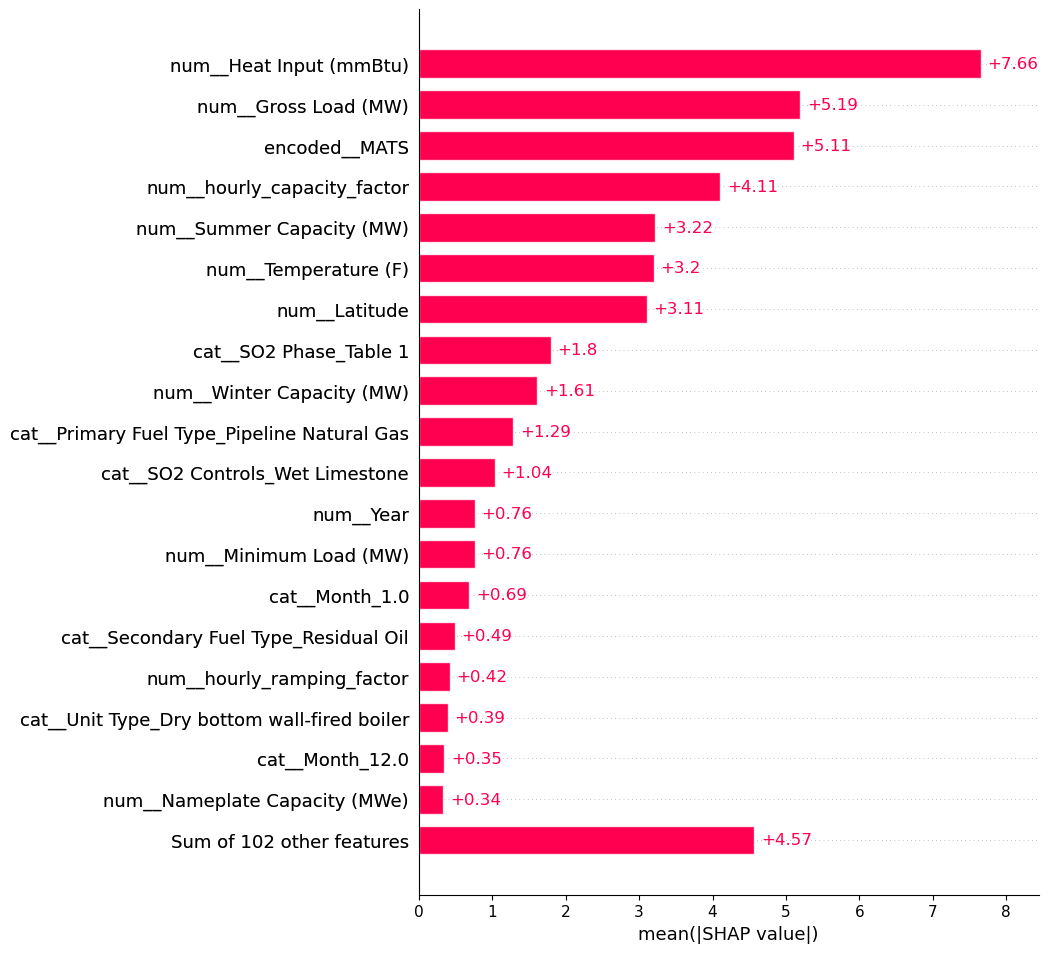

In [26]:
shap.plots.bar(shap_values, max_display=20)

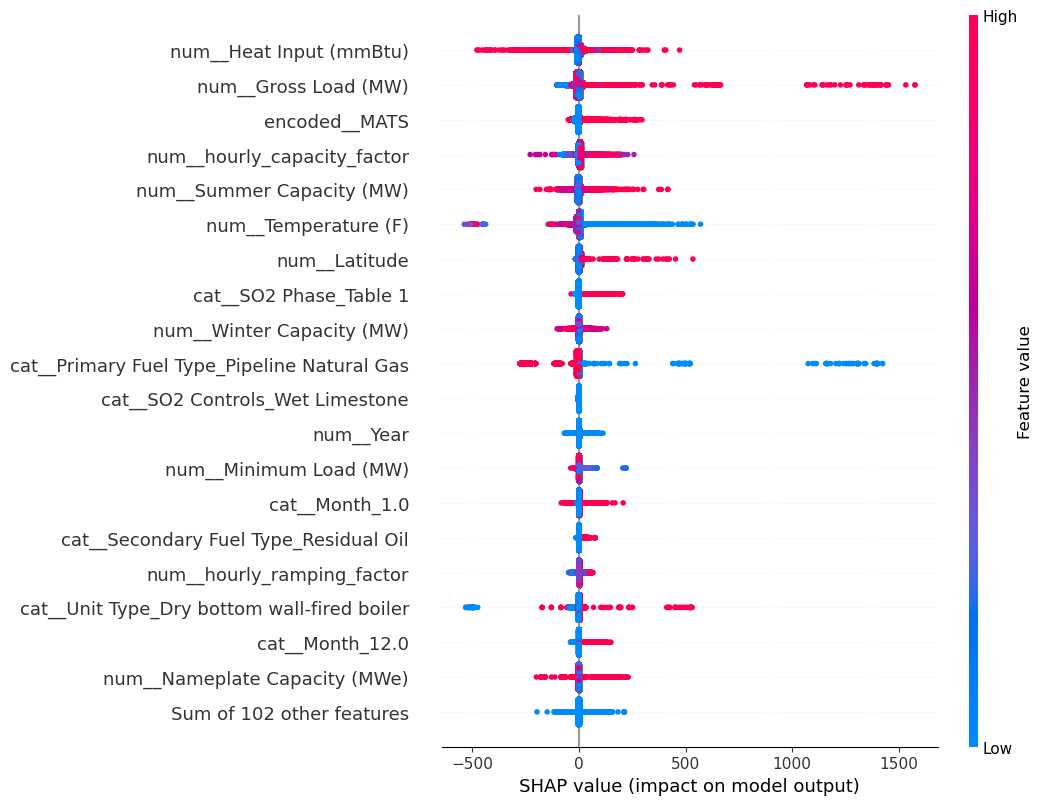

In [33]:
shap.plots.beeswarm(shap_values, max_display=20)

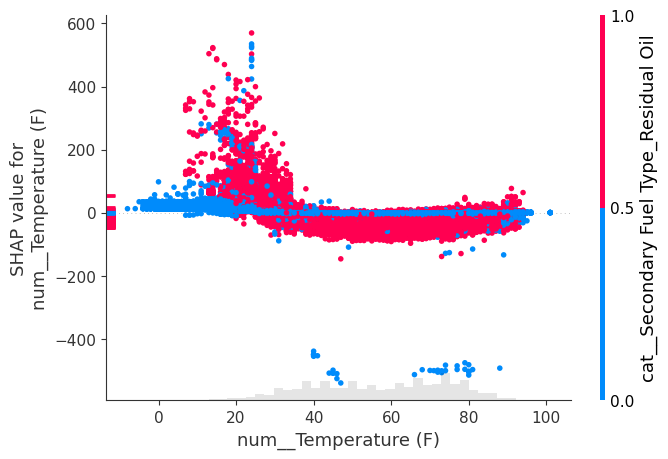

In [ ]:
# we find the same relationship between Temp, Heat Input, and Secondary Fuel Residual Oil here

shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

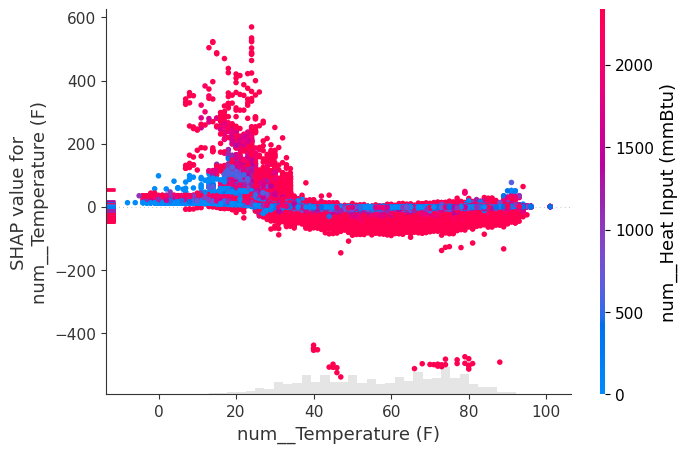

In [35]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

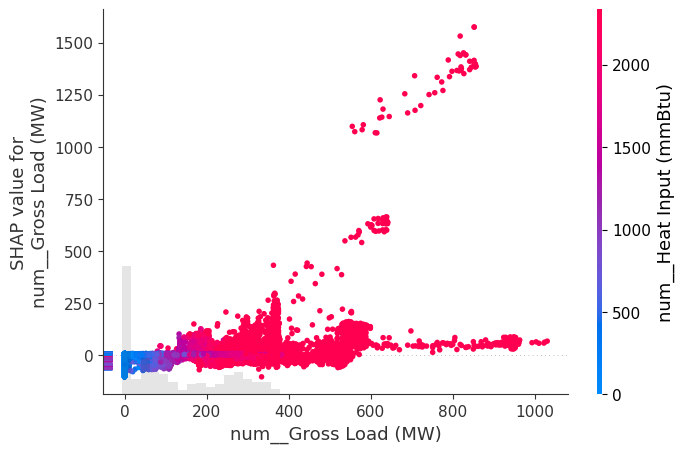

In [34]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

<h5>With Lags</h5>

In [35]:
explainer = shap.TreeExplainer(xgb_default_model)

In [36]:
shap_values = explainer(X_test, approximate=False)

In [39]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl']

In [50]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl")

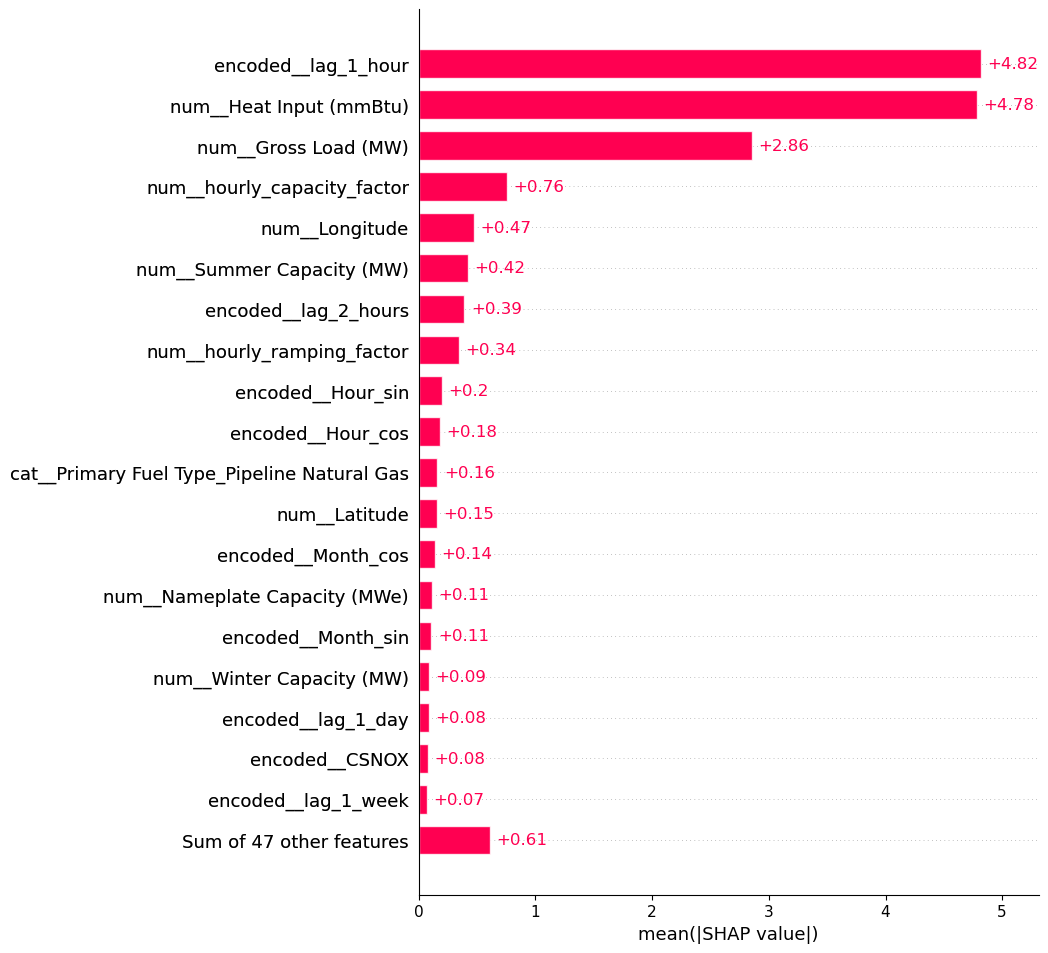

In [51]:
shap.plots.bar(shap_values, max_display=20)